In [ ]:
import os  # for CONSDB_TOKEN


In [1]:
import lsst.afw.math as afwMath
from lsst.afw.math import binImage
import lsst.afw.image as afwImage
from lsst.daf.butler import Butler
from lsst.pipe.tasks.visualizeVisit import VisualizeMosaicExpConfig, VisualizeMosaicExpTask
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm, trange
from photutils.background import Background2D, MedianBackground
from astropy.stats import SigmaClip
from matplotlib.patches import Polygon
from matplotlib.path import Path
from lsst.summit.utils.utils import getCameraFromInstrumentName
from lsst.afw.cameraGeom import FOCAL_PLANE
from matplotlib.path import Path
from photutils.segmentation import detect_sources, detect_threshold
from photutils.utils import circular_footprint
from astropy.convolution import convolve
from photutils.segmentation import make_2dgaussian_kernel
import lsst.summit.utils.plotting as splot

%matplotlib inline 
%matplotlib widget

from lsst.summit.utils import ConsDbClient


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.
        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


In [2]:
def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

def doStarless(img):
    kernel = make_2dgaussian_kernel(3, size=3)   
    threshold = detect_threshold(img, 5.)
    segment_map = detect_sources(img, threshold, npixels=5)
    footprint = circular_footprint(radius=3)
    dilateMask = segment_map.make_source_mask(footprint=footprint)
    dilateAndSmoothMask = convolve(dilateMask, kernel)

    starlessImg = np.where(dilateAndSmoothMask != 0, np.median(img), img)
    return starlessImg

In [3]:
def fitPlane(image, order=1):
    '''
    Function to fit a 1st order Chebyshev polynomial to a binned image

    Parameters
    ----------
    image : `lsst.afw.image._image.ImageF`
        FFP image
    order : `int`
        Order of polynomial to fit

    Returns
    -------
    bkgdImage : `lsst.afw.image._image.ImageF`
        Chebyshev model of image
    '''
    # Hard code fit parameters for the notebook
    undersampleStyle = "INCREASE_NXNYSAMPLE"
    statsCtrl = afwMath.StatisticsControl()
    statsCtrl.setNanSafe(True)

    statsFlag = afwMath.stringToStatisticsProperty("MEAN")
    statsCtrl.setNumSigmaClip(1)
    statsCtrl.setNumIter(1)

    width = image.getWidth()
    height = image.getHeight()

    bctrl = afwMath.BackgroundControl(width, height, statsCtrl, statsFlag)
    bctrl.setUndersampleStyle(undersampleStyle)

    bkgd = afwMath.makeBackground(image, bctrl)
    bkgd.getStatsImage().variance = afwImage.ImageF(np.sqrt(bkgd.getStatsImage().image.array))

    actrl = afwMath.ApproximateControl(afwMath.ApproximateControl.CHEBYSHEV, order, order, True)
    undersampleStyle = afwMath.stringToUndersampleStyle(undersampleStyle)

    approx = bkgd.getApproximate(actrl, undersampleStyle)
    bkgdImage = approx.getImage()

    return bkgdImage


In [4]:
# (Lettura CSV disabilitata - si usano le visite hard-coded nella cella successiva)
# import pandas as pd
# df_stray = pd.read_csv("stray_light_20250703.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'stray_light_20250703.csv'

In [4]:
count = 0
visits = [2026031200632]
print(f"Visita selezionata ({count}): {visits[count]}")


Visita selezionata (0): 2026031200632


In [5]:
repo = "main"
butler = Butler(config=repo,instrument='LSSTCam')

In [6]:
coll = ["u/ataranto/lsst_outputs"]


In [7]:
# ==============================================================================
# CONNESSIONE A CONSDB: ESTRAZIONE SKY BACKGROUND UFFICIALE
# ==============================================================================
vscode = True

if vscode == True:
    URL = "https://usdf-rsp.slac.stanford.edu/consdb"  # for vscode
    tk = os.environ["CONSDB_TOKEN"]  # set in .env (see README)
    cdb_client = ConsDbClient(URL, token=tk)
else:
    URL = "http://consdb-pq.consdb:8080/consdb"
    os.environ["no_proxy"] = os.environ.get("no_proxy", "") + ",.consdb"
    tk = None
    cdb_client = ConsDbClient(URL, token=tk)

query = f"""
    SELECT q.sky_bg, q.sky_noise, v.ccdvisit_id, v.visit_id, v.detector 
    FROM cdb_lsstcam.ccdvisit1 AS v, cdb_lsstcam.ccdvisit1_quicklook AS q
    WHERE v.visit_id = {visits[count]} AND q.ccdvisit_id = v.ccdvisit_id
"""

consdb_bg_dict = {}
consdb_noise_dict = {}

def _to_clean_float(val):
    if val is None:
        return np.nan
    try:
        if hasattr(val, "mask") and bool(val.mask):
            return np.nan
    except Exception:
        pass
    try:
        f = float(val)
        return f if np.isfinite(f) else np.nan
    except (ValueError, TypeError):
        return np.nan

try:
    ccd_table = cdb_client.query(query)
    for row in ccd_table:
        try:
            det = int(row["detector"])
        except Exception:
            continue
        bg = _to_clean_float(row.get("sky_bg") if hasattr(row, "get") else row["sky_bg"])
        noise = _to_clean_float(row.get("sky_noise") if hasattr(row, "get") else row["sky_noise"])
        if not np.isnan(bg):
            consdb_bg_dict[det] = bg
        if not np.isnan(noise):
            consdb_noise_dict[det] = noise
    print(f"ConsDB: recuperati {len(consdb_bg_dict)} CCD per la visita {visits[count]}")
except Exception as e:
    print(f"ATTENZIONE - ConsDB query non riuscita: {e}")

global_median_bg = np.nanmedian(list(consdb_bg_dict.values())) if consdb_bg_dict else np.nan
global_median_noise = np.nanmedian(list(consdb_noise_dict.values())) if consdb_noise_dict else 10.0
print(f"Background ConsDB mediano: {global_median_bg:.2f} ADU, Sky Noise mediano: {global_median_noise:.2f} ADU")


ConsDB: recuperati 189 CCD per la visita 2026031200632
Background ConsDB mediano: 2096.79 ADU, Sky Noise mediano: 46.53 ADU


In [8]:
# ==============================================================================
# CARICAMENTO SENSORE DA BUTLER (PARALLELO A 10 WORKER) E PREPARAZIONE BACKGROUND
# ==============================================================================
binning = 8
badMaskNames = ["NO_DATA", "DETECTED", "DETECTED_NEGATIVE", "SAT", "BAD", "INTRP", "CR"]
current_visit = visits[count]
print(f"Visita in caricamento: {current_visit}")

detects = [i for i in range(189) if i != 122]

import threading
from concurrent.futures import ThreadPoolExecutor, as_completed

_thread_local = threading.local()

def _get_worker_butler():
    if not hasattr(_thread_local, "butler"):
        _thread_local.butler = Butler(config=repo, instrument="LSSTCam")
    return _thread_local.butler

def _fetch_detector(det_id):
    try:
        b = _get_worker_butler()
        dataId = {"instrument": "LSSTCam", "exposure": current_visit, "detector": det_id}
        im = b.get("post_isr_image", dataId=dataId, collections=coll)
        bad_mask_bit = im.mask.getPlaneBitMask(badMaskNames)
        msk = (im.mask.array.astype(int) & bad_mask_bit) != 0
        im.getMaskedImage().image.array[msk] = np.nan
        binned_im = binImage(im.getMaskedImage(), binning)

        # Modello di background ConsDB per questo sensore
        bg_val = consdb_bg_dict.get(
            det_id, 
            global_median_bg if np.isfinite(global_median_bg) else float(np.nanmedian(binned_im.image.array))
        )
        bkg_im = binned_im.clone()
        bkg_im.image.array[:, :] = bg_val

        return det_id, binned_im, bkg_im
    except Exception:
        return det_id, None, None

pIsrImsBinned = []
pBkgImsBinned = []
ids = []

binned_results = {}
with ThreadPoolExecutor(max_workers=10) as executor:
    futures = [executor.submit(_fetch_detector, d) for d in detects]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Download sensori (10 worker)"):
        det_id, b_im, bkg_im = fut.result()
        if b_im is not None:
            binned_results[det_id] = (b_im, bkg_im)

for det_id in sorted(binned_results.keys()):
    ids.append(det_id)
    b_im, bkg_im = binned_results[det_id]
    pIsrImsBinned.append(b_im)
    pBkgImsBinned.append(bkg_im)

print(f"Caricati con successo {len(ids)} sensori.")


Visita in caricamento: 2026031200632


Download sensori (10 worker): 100%|██████████| 188/188 [02:44<00:00,  1.14it/s]

Caricati con successo 188 sensori.


### USE THIS CELL TO RUN WITH THE REAL ON-SKY IMAGE FROM THE BUTLER ###

Clicca 4 punti sull'immagine per definire i vertici del poligono.


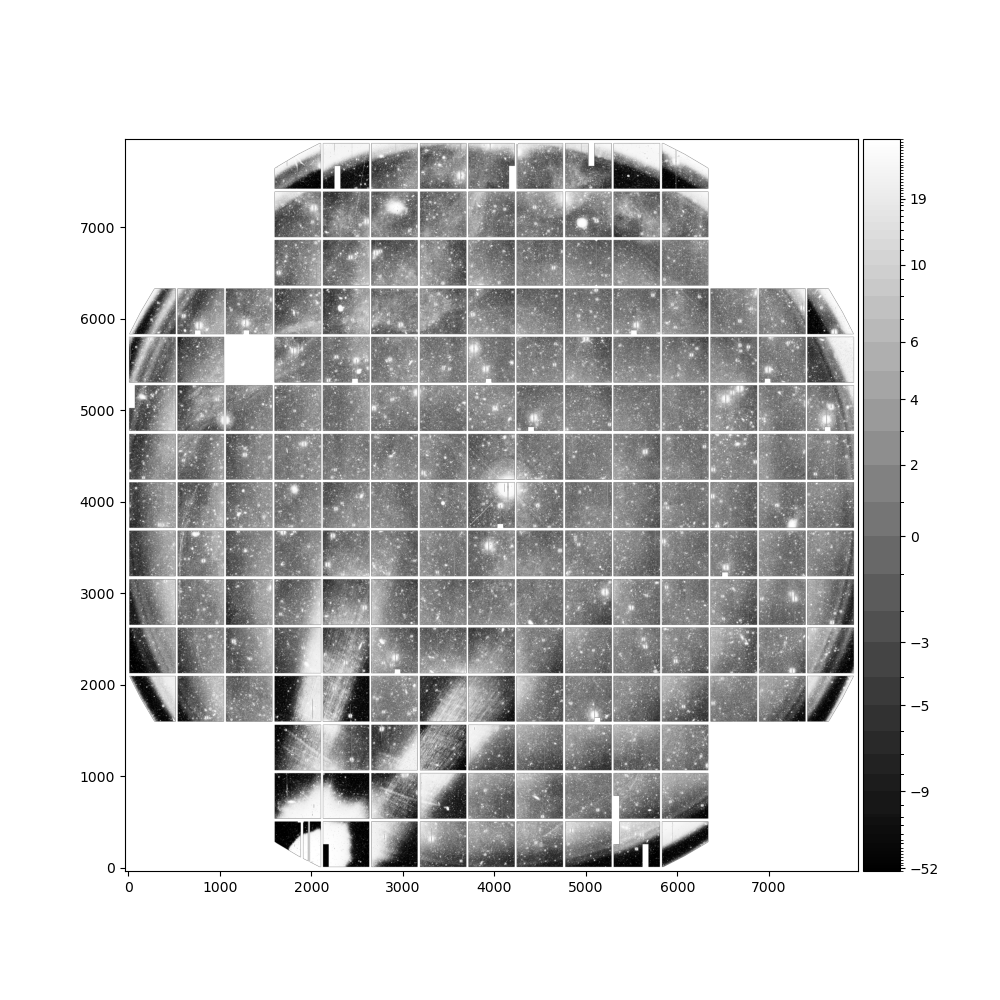

In [9]:
# ==============================================================================
# MOSAICO, SOTTRAZIONE BACKGROUND CONSDB E SELEZIONE POLIGONO A 4 PUNTI
# ==============================================================================
camera = getCameraFromInstrumentName("LSSTCam")
plt.close("all")
mosConfig = VisualizeMosaicExpConfig()
mosConfig.binning = binning
mosTask = VisualizeMosaicExpTask(config=mosConfig)

# 1. Mosaico immagine grezza e mosaico background ConsDB (allineato pixel per pixel)
pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData
pBkgMosaic = mosTask.run(pBkgImsBinned, camera, inputIds=ids).outputData

raw_image = pIsrMosaic.array
bkg_image = pBkgMosaic.array

# 2. Sottrazione diretta del background ConsDB invece di fare il fit con fitPlane
image = raw_image - bkg_image

med = np.nanmedian(image)

fig = plt.figure(figsize=(10, 10))
cb = splot.plot(image, stretch="ccs", figure=fig)
ax = fig.axes[0]

valid_rows = np.where(~np.isnan(image).all(axis=1))[0]
valid_cols = np.where(~np.isnan(image).all(axis=0))[0]
row_min, row_max = valid_rows[0], valid_rows[-1]
col_min, col_max = valid_cols[0], valid_cols[-1]

ax.set_xlim(col_min - 50, col_max + 50)
ax.set_ylim(row_min - 50, row_max + 50)
polygon_points = []

def onclick(event):
    if event.inaxes != ax or event.xdata is None or event.ydata is None:
        return
    polygon_points.append((event.xdata, event.ydata))
    ax.plot(event.xdata, event.ydata, "ro")
    fig.canvas.draw()
    if len(polygon_points) == 4:
        poly = Polygon(polygon_points, closed=True, fill=False, edgecolor="yellow", linewidth=2)
        ax.add_patch(poly)
        fig.canvas.draw()
        fig.canvas.mpl_disconnect(cid)

        global poly_mask
        poly_path = Path(polygon_points)
        ny, nx = image.shape
        yy, xx = np.mgrid[:ny, :nx]
        coords = np.vstack((xx.ravel(), yy.ravel())).T
        poly_mask = poly_path.contains_points(coords).reshape(ny, nx)
        print("Poligono a 4 vertici completato! Esegui la cella successiva per la fotometria.")

cid = fig.canvas.mpl_connect("button_press_event", onclick)
print("Clicca 4 punti sull'immagine per definire i vertici del poligono.")


In [21]:
### USE THIS CELL TO RUN WITH CBP STACKED IMAGE ###

In [10]:
# camera = butler.get("camera", instrument="LSSTCam", collections="LSSTCam/calib/DM-50716/unbounded")
camera = getCameraFromInstrumentName('LSSTCam')
plt.close('all')
mosConfig = VisualizeMosaicExpConfig()
mosConfig.binning = binning
mosTask = VisualizeMosaicExpTask(config=mosConfig)
pIsrMosaic = data_z
# plt.imshow(data_z, cmap='gray', vmin=np.nanpercentile(data_z,5), vmax=np.nanpercentile(data_z,95),origin='lower')

# splot.plot(pIsrMosaic, stretch='ccs')
# Mask out the vignetted region before fitting
med = np.nanmedian(pIsrMosaic)

xCen, yCen = (pIsrMosaic.shape[0]/2, pIsrMosaic.shape[1]/2)
rad = (pIsrMosaic.shape[0] + pIsrMosaic.shape[1])/ 4  # Roughly the vignetted region radius
x = np.arange(1, pIsrMosaic.shape[1]+1)
y = x.reshape(-1, 1)
r = np.sqrt((x - xCen)**2 + (y - yCen)**2)
vignet = r >= rad

vignet = vignet[1:, :]
# clone = pIsrMosaic.clone()
# # Ensure vignet matches the shape of clone.array
# vignet_mask = vignet
# if vignet.shape != clone.shape:
# 	# Adjust vignet to match the shape of clone.array
# 	min_rows = min(vignet.shape[0], clone.shape[0])
# 	min_cols = min(vignet.shape[1], clone.shape[1])
# 	vignet_mask = vignet[:min_rows, :min_cols]
# 	clone = clone[:min_rows, :min_cols]
# clone[vignet_mask] = np.nan
# # First fit, ignoring the vignetted region
# bkgd1 = fitPlane(clone, 2)

# # sigma_clip = SigmaClip(sigma=3.0)
# # bkg_estimator = MedianBackground()
# # bkgd = Background2D(clone.array, (200, 200), filter_size=(3, 3), sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)
# # Now mask out bright residual peaks and fit again
# want = (pIsrMosaic - bkgd1) >= 5
# clone[want] = np.nan
# bkgd = fitPlane(clone, 3)

# fig, ax = plt.subplots(1, 3, figsize=(15, 5))
# ax[0].imshow(pIsrMosaic.array, origin="lower", vmin=med-20, vmax=med+30)
# ax[1].imshow(bkgd.array, origin="lower")
# cb = ax[2].imshow(pIsrMosaic.array - bkgd.array, vmin=-100, vmax=70, origin="lower")
# colorbar(cb)
 
image=pIsrMosaic #- bkgd.array
med = np.nanmedian(image)
# plt.close('all')
fig = plt.figure(figsize=(10, 10))
cb = plt.imshow(image, cmap='gray', vmin=np.nanpercentile(data_z,5), vmax=np.nanpercentile(data_z,95),origin='lower')

# cb = splot.plot(image, stretch='ccs', figure=fig)
ax = fig.axes[0]  # Use the axes created by splot.plot()

polygon_points = []

def onclick(event):
    # Only register clicks inside the axes
    if event.inaxes != ax:
        return
    # Add point
    polygon_points.append((event.xdata, event.ydata))
    # Draw point
    ax.plot(event.xdata, event.ydata, 'ro')
    fig.canvas.draw()
    # If 4 points, draw polygon and disconnect
    if len(polygon_points) == 4:
        poly = Polygon(polygon_points, closed=True, fill=False, edgecolor='yellow', linewidth=2)
        ax.add_patch(poly)
        fig.canvas.draw()
        fig.canvas.mpl_disconnect(cid)
        # Build the mask for use outside the function
        global poly_mask
        poly_path = Path(polygon_points)
        ny, nx = pIsrMosaic.shape
        yy, xx = np.mgrid[:ny, :nx]
        coords = np.vstack((xx.ravel(), yy.ravel())).T
        poly_mask = poly_path.contains_points(coords).reshape(ny, nx)

# After you have clicked 4 times and the polygon is drawn, run this in a new cell:



cid = fig.canvas.mpl_connect('button_press_event', onclick)
print("Click 4 times on the image to define the corners of your polygon.")
# plt.close()

NameError: name 'data_z' is not defined

In [11]:
# ==============================================================================
# FOTOMETRIA, BRILLANZA SUPERFICIALE E CONFRONTO CON LO SKY BACKGROUND
# ==============================================================================
detector_corners = {}
for det in camera:
    corners = det.getCorners(FOCAL_PLANE)
    corners_fp_arr = np.array([[pt.getX(), pt.getY()] for pt in corners])
    detector_corners[det.getId()] = corners_fp_arr

poly_points = np.array(polygon_points)
poly_points_mm_centered = (poly_points - (image.shape[1] / 2)) * (
    np.abs(np.min(detector_corners[0])) / (image.shape[1] / 2)
)

det_ids_in_poly = []
for det_id, corners in detector_corners.items():
    det_path = Path(corners)
    poly_path = Path(poly_points_mm_centered)
    min_x, min_y = np.min(poly_points_mm_centered, axis=0)
    max_x, max_y = np.max(poly_points_mm_centered, axis=0)
    grid_x, grid_y = np.meshgrid(
        np.linspace(min_x, max_x, 100),
        np.linspace(min_y, max_y, 100)
    )
    grid_points = np.vstack([grid_x.ravel(), grid_y.ravel()]).T
    inside_poly = poly_path.contains_points(grid_points)
    poly_interior_points = grid_points[inside_poly]
    if np.any(det_path.contains_points(poly_interior_points)):
        det_ids_in_poly.append(det_id)

print("Detector IDs dove cade il poligono:", det_ids_in_poly)

# Pixel nel poligono
net_pixels = image[poly_mask]
net_pixels = net_pixels[np.isfinite(net_pixels)]

raw_pixels = raw_image[poly_mask]
raw_pixels = raw_pixels[np.isfinite(raw_pixels)]

bkg_pixels = bkg_image[poly_mask]
bkg_pixels = bkg_pixels[np.isfinite(bkg_pixels)]

num_pixels = len(net_pixels)
net_flux_median = float(np.median(net_pixels))
net_flux_mean = float(np.mean(net_pixels))
raw_flux_median = float(np.median(raw_pixels))
sky_flux_median = float(np.median(bkg_pixels))

# Area in arcsec2 di un superpixel binnato (scala Rubin: 0.2 arcsec/px nativo)
pixel_area_arcsec2 = (0.2 * binning) ** 2  # (0.2 * 8)^2 = 2.56 arcsec^2

# Calibrazione fotometrica sui detector che intersecano il poligono
mag_obj = []
mag_sky = []

for det in det_ids_in_poly:
    if det not in [120, 121, 122]:
        try:
            dataId = {"instrument": "LSSTCam", "detector": det, "visit": visits[count]}
            exp = butler.get("preliminary_visit_image", dataId=dataId, collections=coll)

            # Surface brightness oggetto (netto)
            if net_flux_median > 0:
                m_obj = exp.photoCalib.instFluxToMagnitude(net_flux_median / pixel_area_arcsec2)
                mag_obj.append(m_obj)

            # Surface brightness fondo cielo ConsDB
            if sky_flux_median > 0:
                m_sky = exp.photoCalib.instFluxToMagnitude(sky_flux_median / pixel_area_arcsec2)
                mag_sky.append(m_sky)

            print(f"Det {det:3d}:  SB_oggetto = {m_obj:.4f} mag/arcsec²,  SB_cielo = {m_sky:.4f} mag/arcsec²")
        except Exception as e:
            print(f"Det {det:3d}: non calibrato ({e})")
            continue

mean_sb_obj = float(np.mean(mag_obj)) if len(mag_obj) > 0 else np.nan
mean_sb_sky = float(np.mean(mag_sky)) if len(mag_sky) > 0 else np.nan

# ----------------------------------------------------------------------
# CONFRONTO DIRETTO: OGGETTO vs SKY BACKGROUND
# ----------------------------------------------------------------------
contrast_pct = (net_flux_median / sky_flux_median) * 100.0 if sky_flux_median > 0 else 0.0
delta_mag = (mean_sb_obj - mean_sb_sky) if (np.isfinite(mean_sb_obj) and np.isfinite(mean_sb_sky)) else np.nan

# Rumore di cielo ConsDB per i detector coinvolti
involved_noises = [consdb_noise_dict[d] for d in det_ids_in_poly if d in consdb_noise_dict]
sky_noise_val = float(np.median(involved_noises)) if len(involved_noises) > 0 else global_median_noise
binned_sky_noise = sky_noise_val / binning if binning > 0 else sky_noise_val
snr = (net_flux_median / binned_sky_noise) if (binned_sky_noise and binned_sky_noise > 0) else np.nan

print("\n" + "=" * 70)
print("          BRILLANZA SUPERFICIALE ED IMPATTO SUL FONDO CIELO")
print("=" * 70)
print(f"Visita analizzata:                     {visits[count]}")
print(f"Pixel usati nel poligono:              {num_pixels} px")
print(f"Fondo cielo ConsDB (mediana):          {sky_flux_median:.2f} ADU / px binnato")
print(f"Conteggio grezzo (mediana):            {raw_flux_median:.2f} ADU / px binnato")
print(f"Segnale netto oggetto (mediana):       {net_flux_median:.2f} ADU / px binnato")
print(f"Segnale netto oggetto (media):         {net_flux_mean:.2f} ADU / px binnato")
print("-" * 70)
print(f"Brillanza Superficiale OGGETTO (SB):   {mean_sb_obj:.4f} mag / arcsec²")
print(f"Brillanza Superficiale FONDO CIELO:    {mean_sb_sky:.4f} mag / arcsec²")
print("-" * 70)
print("POSIZIONAMENTO RISPETTO ALLO SKY BACKGROUND:")
print(f"  - Contrasto relativo:                +{contrast_pct:.2f}% sopra il fondo cielo")
print(f"  - Differenza di magnitudine (Δμ):    {delta_mag:+.4f} mag / arcsec²")
if np.isfinite(delta_mag):
    fainter_brighter = "più debole" if delta_mag > 0 else "più luminoso"
    print(f"                                       (l'oggetto è {abs(delta_mag):.2f} mag {fainter_brighter} del cielo)")
print(f"  - Rapporto Segnale / Rumore (SNR):   {snr:.2f} σ (rumore cielo: {binned_sky_noise:.2f} ADU/px)")
print("=" * 70)


Detector IDs dove cade il poligono: [1, 2, 4, 5, 8, 12, 15, 16, 45, 46, 47, 48, 49]


/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/share/eups/Linux64/obs_base/g00893bd134+caafe9eba2/python/lsst/obs/base/formatters/fitsExposure.py:798: FutureWarning: Summary fields [centroidDiffShapeletsVsSlotMedian, nShapeletsStar, psfAdaptiveIncludeThresholdMultiplier, psfAdaptiveThresholdValue, refCatSourceDensity, shapeletsCoeffs, shapeletsIqScore, shapeletsOnlyIqScore, shapeletsStarEMedian, shapeletsStarUnNormalizedEMedian, starComa1Median, starComa2Median, starE41Median, starE42Median, starKurtosisMedian, starTrefoil1Median, starTrefoil2Median] not recognized by this software version; ignoring them.
  result = self.reader.read(**self.checked_parameters, dtype=self.storageClass_dtype)


Det   1:  SB_oggetto = 31.1171 mag/arcsec²,  SB_cielo = 24.6594 mag/arcsec²
Det   2:  SB_oggetto = 31.1228 mag/arcsec²,  SB_cielo = 24.6652 mag/arcsec²
Det   4:  SB_oggetto = 31.1330 mag/arcsec²,  SB_cielo = 24.6753 mag/arcsec²
Det   5:  SB_oggetto = 31.1336 mag/arcsec²,  SB_cielo = 24.6759 mag/arcsec²
Det   8:  SB_oggetto = 31.1425 mag/arcsec²,  SB_cielo = 24.6848 mag/arcsec²
Det  12:  SB_oggetto = 31.1364 mag/arcsec²,  SB_cielo = 24.6788 mag/arcsec²
Det  15:  SB_oggetto = 31.1454 mag/arcsec²,  SB_cielo = 24.6878 mag/arcsec²
Det  16:  SB_oggetto = 31.1428 mag/arcsec²,  SB_cielo = 24.6851 mag/arcsec²
Det  45:  SB_oggetto = 31.1499 mag/arcsec²,  SB_cielo = 24.6922 mag/arcsec²
Det  46:  SB_oggetto = 31.1480 mag/arcsec²,  SB_cielo = 24.6903 mag/arcsec²
Det  47:  SB_oggetto = 31.1459 mag/arcsec²,  SB_cielo = 24.6882 mag/arcsec²
Det  48:  SB_oggetto = 31.1507 mag/arcsec²,  SB_cielo = 24.6931 mag/arcsec²
Det  49:  SB_oggetto = 31.1468 mag/arcsec²,  SB_cielo = 24.6892 mag/arcsec²

          B

In [ ]:
count=count+1
plt.close("all ")

In [ ]:
# ==============================================================================
# ISTOGRAMMI DIAGNOSTICI: DISTRIBUZIONE PIXEL E CONFRONTO CON IL FONDO
# ==============================================================================
pixels_net = image[poly_mask]
pixels_net = pixels_net[np.isfinite(pixels_net)]

pixels_raw = raw_image[poly_mask]
pixels_raw = pixels_raw[np.isfinite(pixels_raw)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Conteggi grezzi vs fondo ConsDB
axes[0].hist(pixels_raw, bins=50, alpha=0.7, color="steelblue", edgecolor="k")
axes[0].axvline(sky_flux_median, color="orange", linewidth=2, linestyle="--", label=f"Fondo ConsDB: {sky_flux_median:.1f} ADU")
axes[0].axvline(raw_flux_median, color="red", linewidth=2, label=f"Mediana Grezza: {raw_flux_median:.1f} ADU")
axes[0].set_xlabel("Conteggio Grezzo [ADU / px binnato]")
axes[0].set_ylabel("Numero di pixel")
axes[0].set_title(f"Conteggi Grezzi vs Fondo ConsDB\n(Eccesso: +{contrast_pct:.2f}% sopra il cielo)")
axes[0].legend()

# 2. Segnale netto dell'oggetto
axes[1].hist(pixels_net, bins=50, alpha=0.7, color="crimson", edgecolor="k")
axes[1].axvline(0, color="gray", linestyle=":", linewidth=1.5, label="Fondo (0)")
axes[1].axvline(net_flux_median, color="darkred", linewidth=2, label=f"Mediana Netta: {net_flux_median:.2f} ADU")
axes[1].set_xlabel("Segnale Netto [ADU / px binnato] (Raw - ConsDB)")
axes[1].set_ylabel("Numero di pixel")
axes[1].set_title(f"Segnale Netto Oggetto\n(SB = {mean_sb_obj:.2f} mag/arcsec², Δμ = {delta_mag:+.2f} mag)")
axes[1].legend()

plt.tight_layout()
plt.show()
